# 02 · Manifold — Geistlinger 2020 HGSOC

Fit a cell-state trajectory to the integrated malignant manifold and root it by **developmental order**.
Branching is tested **honestly**: a scFates PPT *tree* is fit first and its tips characterised. If the tips
resolve a Gast-leaning arm against a pSom-leaning arm, the topology is a genuine bifurcation (tree, -> Gate 3).
If instead the tips all lean the same way and differ only in the terminal Crest readout / proliferation, the
"branches" are density+cycling structure inside one co-varying programme -> the manifold is **non-branching**
and a `curve` is the correct model. Signature scores are graph-smoothed (kNN averaging) for reading geography;
raw scores are shown in the 03 deliverable UMAPs. Deliverable: `manifold.h5ad`, `manifold.pdf`.

In [1]:
import os, sys, glob, warnings, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('malignant manifold:', adata.shape[0], 'cells on the joint embedding')
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
from numpy.linalg import svd
u,s,vt = svd(c, full_matrices=False)
print(f'UMAP aspect ratio (major/minor std): {s[0]/s[1]:.2f}')

malignant manifold: 5906 cells on the joint embedding
UMAP aspect ratio (major/minor std): 4.80


In [4]:
# module signatures with the union control pool; graph-smoothed copies for geography
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
label = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src,lab in label.items():
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]
adata.obs['cyc'] = adata.obs[['g1s_score','g2m_score']].apply(pd.to_numeric, errors='coerce').fillna(0).max(1)

Gast: 66/81 genes present
pSom: 78/98 genes present
Crest: 95/104 genes present


In [5]:
# smoothed spatial correlations decide branching-vs-collapsed geometry
print('smoothed spatial correlations on the whole manifold:')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm'),
            ('cyc','Gast_sm'),('cyc','pSom_sm'),('cyc','Crest_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
print('\nper-compartment smoothed developmental means:')
print(adata.obs.groupby('compartment', observed=True)[['Gast_sm','pSom_sm','Crest_sm','cyc']].mean().round(3).to_string())
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
frac = adata.obs.loc[hi.values,'compartment'].value_counts(normalize=True).round(2).to_dict()
print('\nCrest-high decile spread across compartments:', frac)
print('-> Gast/pSom CO-VARY and both oppose Crest; cycling is a weaker secondary gradient partly aligned')
print('   with the pSom-high origin. Developmental axis spans both compartments -> keep whole manifold.')

smoothed spatial correlations on the whole manifold:
  Gast_sm vs pSom_sm: r = +0.63
  Crest_sm vs Gast_sm: r = -0.79
  Crest_sm vs pSom_sm: r = -0.95
  cyc vs Gast_sm: r = +0.25
  cyc vs pSom_sm: r = +0.46
  cyc vs Crest_sm: r = -0.46

per-compartment smoothed developmental means:
                   Gast_sm  pSom_sm  Crest_sm    cyc
compartment                                         
Cycling/Metabolic    0.220    0.489    -0.429  0.569
Embryonic            0.132    0.328    -0.234  0.186

Crest-high decile spread across compartments: {'Embryonic': 1.0, 'Cycling/Metabolic': 0.0}
-> Gast/pSom CO-VARY and both oppose Crest; cycling is a weaker secondary gradient partly aligned
   with the pSom-high origin. Developmental axis spans both compartments -> keep whole manifold.


**Honest branching test.** A PPT *tree* is fit at the Puram-scale settings and each tip's local
biology is read off the smoothed scores. A genuine bifurcation requires **one Gast-leaning tip opposed to
one pSom-leaning tip**. Here every tip is pSom-leaning (pSom > Gast at all tips) and the tips separate only
by Crest / cycling — there is no Gast arm. The "forks" are density and proliferation structure inside a
single co-varying Gast/pSom programme, so the manifold is **non-branching** and a `curve` is fit.

In [6]:
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.tree(adata, method='ppt', Nodes=200, ppt_lambda=2000, ppt_sigma=.5,
                use_rep='X_umap', seed=SEED, plot=False)
B = np.asarray(adata.uns['graph']['B']); deg = (B>0).sum(0)
tips = np.where(deg==1)[0]; forks = np.where(deg>=3)[0]
Rr = np.asarray(adata.obsm['X_R']); hard = Rr.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
print(f'PPT tree: {len(tips)} tips, {len(forks)} branch nodes (deg>=3)')
lean=[]
for tp in tips:
    m = np.isin(hard, np.where(D[tp]<=4)[0])
    gm,pm = adata.obs.Gast_sm[m].mean(), adata.obs.pSom_sm[m].mean()
    lean.append('Gast' if gm>pm else 'pSom')
    print(f'  tip {tp}: Gast={gm:+.3f} pSom={pm:+.3f} Crest={adata.obs.Crest_sm[m].mean():+.3f} '
          f'cyc={adata.obs.cyc[m].mean():.2f} -> {lean[-1]}-leaning')
print(f'\ntip leanings: {lean}')
print('genuine bifurcation needs a Gast tip AND a pSom tip ->',
      'BRANCHING' if ('Gast' in lean and 'pSom' in lean) else 'NON-BRANCHING (all tips pSom-leaning; fit curve)')

PPT tree: 3 tips, 1 branch nodes (deg>=3)
  tip 131: Gast=+0.037 pSom=+0.268 Crest=-0.140 cyc=0.01 -> pSom-leaning
  tip 160: Gast=+0.235 pSom=+0.611 Crest=-0.454 cyc=0.67 -> pSom-leaning
  tip 171: Gast=+0.199 pSom=+0.600 Crest=-0.527 cyc=1.10 -> pSom-leaning

tip leanings: ['pSom', 'pSom', 'pSom']
genuine bifurcation needs a Gast tip AND a pSom tip -> NON-BRANCHING (all tips pSom-leaning; fit curve)


In [7]:
# fit the curve + fold-free diagnostic (independent of the UMAP neighbour graph)
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3: dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    return dmin/med, int(((B>0).sum(0)==1).sum()), int(((B>0).sum(0)>=3).sum())
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(adata, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips_c, forks_c = fold_diag(adata)
ok = (forks_c == 0 and sa > 1)
print(f'curve: {tips_c} tips, {forks_c} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
print('curve topology check:', 'PASS (fold-free, non-branching)' if ok else 'FAIL')
assert ok

curve: 2 tips, 0 forks | fold self-approach ratio = 2.99 (>1 = fold-free)
curve topology check: PASS (fold-free, non-branching)


In [8]:
# derive root at the Gast/pSom-high (Crest-low) developmental origin; Crest is LATE
B = np.asarray(adata.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
Rr = np.asarray(adata.obsm['X_R']); hard = Rr.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (adata.obs.Gast_sm[m].mean(), adata.obs.pSom_sm[m].mean(), adata.obs.Crest_sm[m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low developmental origin)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(adata, root); scf.tl.pseudotime(adata, n_map=1, seed=SEED)
t = adata.obs['t'].values
print('gradient along pseudotime (Spearman rho on smoothed scores):')
for s in ['Gast_sm','pSom_sm','Crest_sm','cyc']:
    rho,p = spearmanr(t, adata.obs[s]); print(f'  {s}: rho={rho:+.3f} p={p:.1e}')
tn = (t-t.min())/(t.max()-t.min())
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
print(f'Crest-high decile mean pseudotime = {tn[hi.values].mean():.2f} (terminal if ~1)')

tip 0: Gast=+0.2208 pSom=+0.4641 Crest=-0.4229
tip 2: Gast=+0.1006 pSom=+0.2441 Crest=-0.1638
derived root = tip 0 (Gast/pSom-high, Crest-low developmental origin)
gradient along pseudotime (Spearman rho on smoothed scores):
  Gast_sm: rho=-0.785 p=0.0e+00
  pSom_sm: rho=-0.630 p=0.0e+00
  Crest_sm: rho=+0.787 p=0.0e+00
  cyc: rho=-0.468 p=0.0e+00
Crest-high decile mean pseudotime = 0.98 (terminal if ~1)


In [9]:
# orient the embedding so pseudotime runs left -> right (house linear layout)
xy = adata.obsm['X_umap'].copy(); t = adata.obs['t'].values
# principal-axis rotation so the trajectory lies horizontal, then sign so low pt is left
c = xy - xy.mean(0); u,sv,vt = np.linalg.svd(c, full_matrices=False)
xyr = c @ vt.T
r = float(np.corrcoef(xyr[:,0], t)[0,1])
if r < 0: xyr[:,0] = -xyr[:,0]; r = -r
adata.obsm['X_umap_lin'] = xyr
print(f'orientation: principal-axis; corr(x_lin, pseudotime) = {r:+.2f}')

orientation: principal-axis; corr(x_lin, pseudotime) = +0.99


saved manifold.h5ad + manifold.pdf


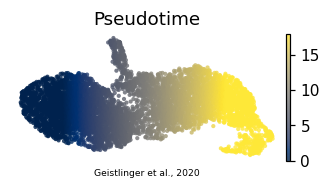

In [10]:
# sanitize non-serializable ElPiGraph uns entry, save
if 'epg' in adata.uns:
    adata.uns['epg'] = {'NodePositions': np.asarray(adata.uns['epg']['NodePositions'])}
adata.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = adata.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Geistlinger et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf')